# Bone fracture CNN evaluation

Uses the active CNN architecture, class mapping, inference loader, preprocessing and test folders. No retraining. Checkpoint incompatibility is reported clearly.

No notebook retrains a model. Missing inputs are reported as unavailable.

## Configuration and split counts

Positive class is `fractured`. Checkpoint extension `.keras` is historical; current implementation loads a PyTorch state dictionary. The active loader validates architecture and preprocessing versions.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT)); sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT); OUT=ROOT/'results'
import torch,pandas as pd,matplotlib.pyplot as plt
from src.bone_fracture_detection.config import *
from src.bone_fracture_detection.model import build_fracture_cnn
root=XRAY_DATASET_DIR; print('size',XRAY_IMAGE_SIZE,'classes',XRAY_CLASS_NAMES,'device cuda',torch.cuda.is_available(),'checkpoint',XRAY_MODEL_PATH); print('trainable parameters',sum(p.numel() for p in build_fracture_cnn().parameters() if p.requires_grad))
counts={s:{c:len(list((root/s/c).glob('*'))) if (root/s/c).exists() else 0 for c in XRAY_CLASS_NAMES} for s in ['train','val','test']}; display(pd.DataFrame(counts))


size (224, 224) classes ('fractured', 'not fractured') device cuda True checkpoint D:\DevLab\Projects\CDSS_Final\models\bone_fracture_detection\fracture_cnn.keras
trainable parameters 4977314


,train,val,test
fractured,4606,337,238
not fractured,4640,492,268


## Actual test inference and metrics

Uses actual model logits, softmax class scores, and saved validation threshold. If checkpoint version does not match current architecture, evaluation stops with the reason. Scores are uncalibrated.

unreadable IMG0004134.jpg image file is truncated (1 bytes not processed)
unreadable IMG0004143.jpg image file is truncated (10 bytes not processed)
unreadable IMG0004148.jpg image file is truncated (14 bytes not processed)
unreadable IMG0004149.jpg image file is truncated (33 bytes not processed)
unreadable IMG0004308.jpg image file is truncated (40 bytes not processed)
unreadable IMG0004347.jpg image file is truncated (40 bytes not processed)
{'n': 500, 'accuracy': 0.976, 'precision_fracture': 0.9788135593220338, 'sensitivity_fractured': np.float64(0.9705882352941176), 'specificity_not_fractured': np.float64(0.9809160305343512), 'f1_fracture': 0.9746835443037974, 'confusion_matrix': [[231, 7], [5, 257]], 'threshold': 0.42503443360328674, 'roc_auc': 0.9993264481365065, 'pr_auc': 0.9992683819254943}
               precision    recall  f1-score   support

    fractured       0.98      0.97      0.97       238
not fractured       0.97      0.98      0.98       262

     accuracy         

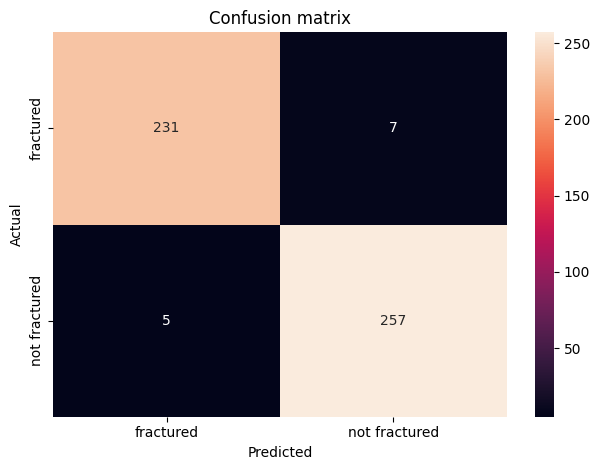

In [2]:
import numpy as np
from PIL import Image
from sklearn.metrics import *
from src.bone_fracture_detection.preprocessing import preprocess_image
from src.bone_fracture_detection.inference import _load_model
try:
 model,device,threshold=_load_model(); rows=[]
 for yi,cls in enumerate(XRAY_CLASS_NAMES):
  for f in sorted((root/'test'/cls).glob('*')):
   try:
    with Image.open(f) as im: x=preprocess_image(im).unsqueeze(0).to(device)
    with torch.inference_mode(): prob=torch.softmax(model(x),1)[0].cpu().numpy()
    pred=0 if prob[0]>=threshold else 1; rows.append({'id':f.name,'path':str(f),'true':yi,'pred':pred,'fracture_score':prob[0],'confidence':prob[pred]})
   except Exception as e: print('unreadable',f.name,str(e))
 d=pd.DataFrame(rows); y=d.true; yp=d.pred; cm=confusion_matrix(y,yp,labels=[0,1]); tn,fp,fn,tp=cm.ravel(); metrics={'n':len(d),'accuracy':accuracy_score(y,yp),'precision_fracture':precision_score(y,yp,pos_label=0,zero_division=0),'sensitivity_fractured':cm[0,0]/(cm[0,0]+cm[0,1]) if cm[0,0]+cm[0,1] else None,'specificity_not_fractured':cm[1,1]/(cm[1,1]+cm[1,0]) if cm[1,1]+cm[1,0] else None,'f1_fracture':f1_score(y,yp,pos_label=0,zero_division=0),'confusion_matrix':cm.tolist(),'threshold':threshold}
 if len(set(y))==2: metrics.update(roc_auc=roc_auc_score(y==0,d.fracture_score),pr_auc=average_precision_score(y==0,d.fracture_score))
 print(metrics); print(classification_report(y,yp,target_names=XRAY_CLASS_NAMES,zero_division=0)); d.to_csv(OUT/'tables/fracture_predictions.csv',index=False); d[d.true!=d.pred].to_csv(OUT/'tables/fracture_errors.csv',index=False); save(OUT/'metrics/fracture_cnn.json',meta(ROOT,'fracture_cnn',metrics=metrics,checkpoint=str(XRAY_MODEL_PATH),test=str(root/'test')))
 import seaborn as sns
 sns.heatmap(cm,annot=True,fmt='d',xticklabels=XRAY_CLASS_NAMES,yticklabels=XRAY_CLASS_NAMES);plt.xlabel('Predicted');plt.ylabel('Actual');plt.title('Confusion matrix');plt.tight_layout();plt.savefig(OUT/'figures/fracture_confusion_matrix.png',dpi=150);plt.show()
except Exception as e: print('UNAVAILABLE: active checkpoint/model evaluation failed:',type(e).__name__,str(e))


## Limitations

The handoff reports at least 294 identical train/test image pairs; folder-split scores are not independent. No saved training history means no learning curves. This binary model does not localize fractures. No compatible baseline weights are available; baseline comparison is NOT RUN.

## Additional test-set visual analysis

The figures below are generated only after successful inference. Selected X-rays are shown unchanged with true and predicted class labels. Confidence is the selected softmax score and is not calibration-validated.

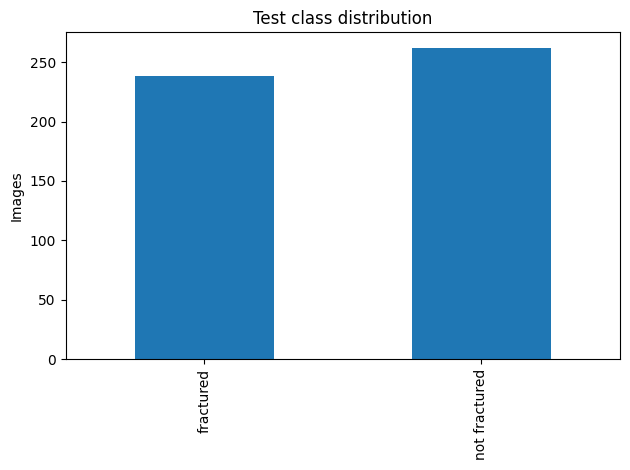

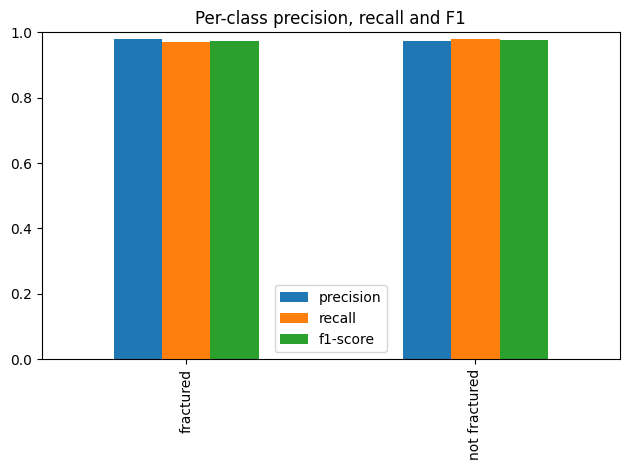

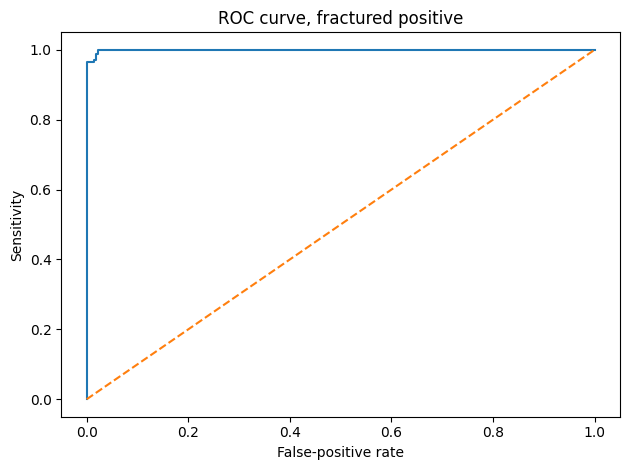

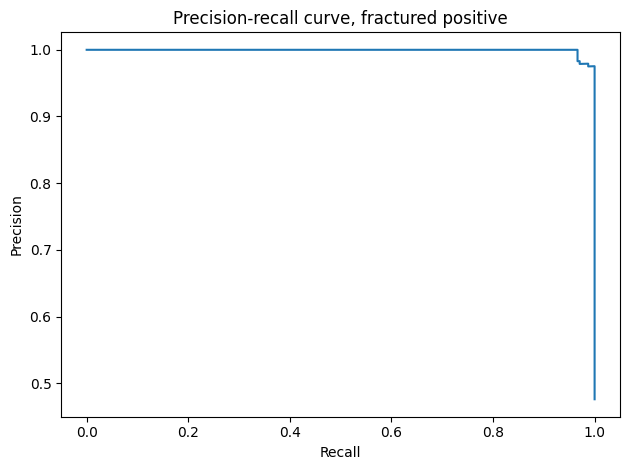

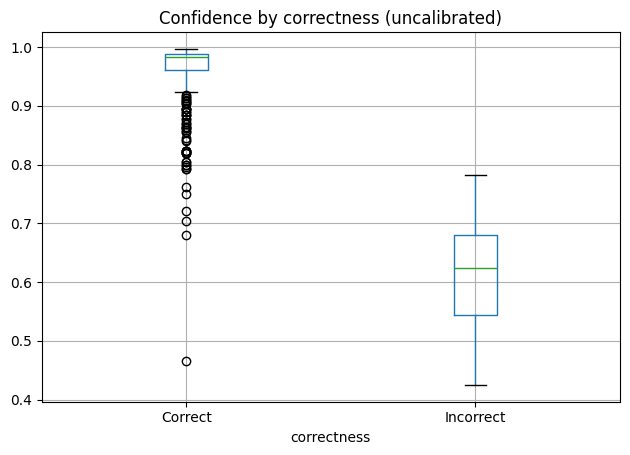

,id,true,pred,fracture_score,confidence
1,00001.png,0,1,0.375955,0.624045
9,001.png,0,1,0.375955,0.624045
23,01.png,0,1,0.375955,0.624045
33,11111.png,0,1,0.375955,0.624045
34,15.png,0,1,0.319104,0.680896
76,616156.png,0,1,0.319104,0.680896
77,65611.png,0,1,0.319104,0.680896
404,52-rotated2-rotated1-rotated3.jpg,1,0,0.563403,0.563403
458,IMG0000181.jpg,1,0,0.781770,0.781770
491,IMG0004310.jpg,1,0,0.488408,0.488408


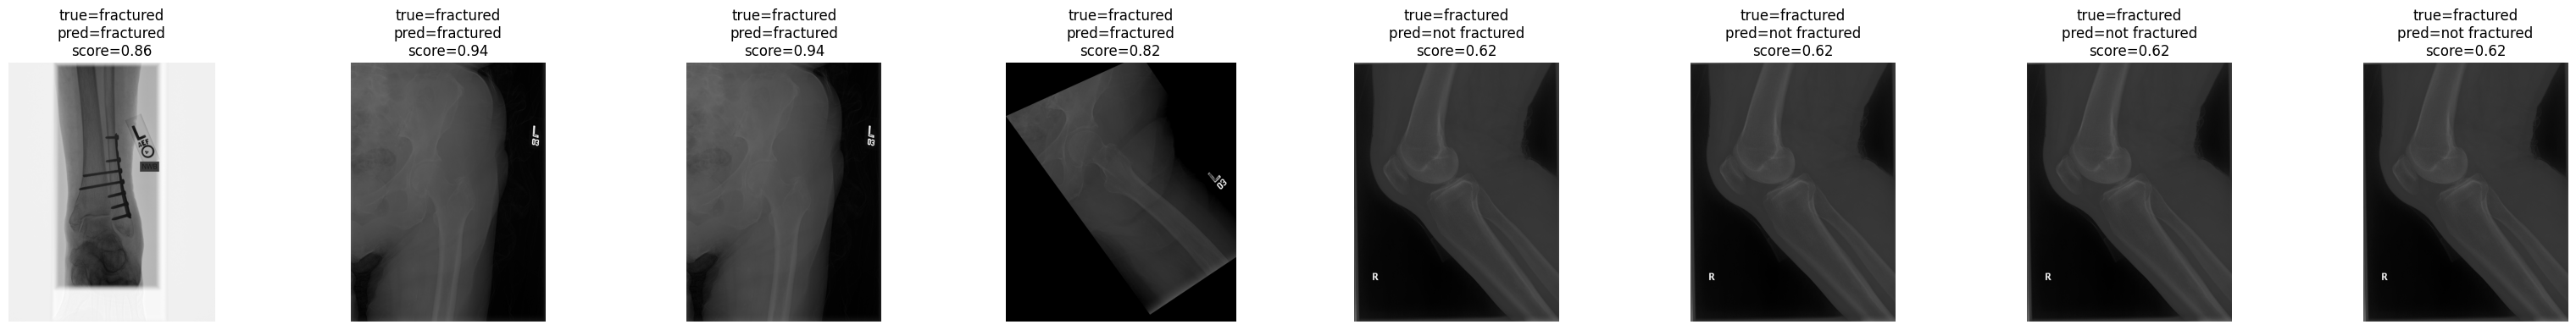

In [4]:
if 'd' in globals() and len(d):
 import seaborn as sns
 from sklearn.metrics import classification_report,roc_curve,precision_recall_curve
 names=list(XRAY_CLASS_NAMES); yy=d.true.to_numpy(); pp=d.pred.to_numpy(); ss=d.fracture_score.to_numpy()
 report=classification_report(yy,pp,target_names=names,output_dict=True,zero_division=0);pd.DataFrame({m:[report[n][m] for n in names] for m in ['precision','recall','f1-score']},index=names).plot.bar(ylim=(0,1),title='Per-class precision, recall and F1');plt.tight_layout();plt.savefig(OUT/'figures/fracture_per_class_metrics.png',dpi=150);plt.show()
 fpr,tpr,_=roc_curve(yy==0,ss);plt.plot(fpr,tpr);plt.plot([0,1],[0,1],'--');plt.xlabel('False-positive rate');plt.ylabel('Sensitivity');plt.title('ROC curve, fractured positive');plt.tight_layout();plt.savefig(OUT/'figures/fracture_roc.png',dpi=150);plt.show()
 pr,rc,_=precision_recall_curve(yy==0,ss);plt.plot(rc,pr);plt.xlabel('Recall');plt.ylabel('Precision');plt.title('Precision-recall curve, fractured positive');plt.tight_layout();plt.savefig(OUT/'figures/fracture_pr.png',dpi=150);plt.show()
 d_plot = d.assign(correctness=np.where(d['true'].eq(d['pred']), 'Correct', 'Incorrect'))
 d_plot.boxplot(column='confidence', by='correctness')
 plt.title('Confidence by correctness (uncalibrated)')
 plt.suptitle('')
 plt.tight_layout()
 plt.savefig(OUT/'figures/fracture_confidence.png', dpi=150)
 plt.show()
 errors=d[d.true!=d.pred]; display(errors[['id','true','pred','fracture_score','confidence']]);
 from PIL import Image
 show=pd.concat([d[d.true==d.pred].head(4),errors.head(4)]).drop_duplicates('id')
 fig,axes=plt.subplots(1,max(1,len(show)),figsize=(4*max(1,len(show)),4)); axes=np.atleast_1d(axes)
 for ax,(_,row) in zip(axes,show.iterrows()):
  with Image.open(row.path) as im: ax.imshow(im.convert('L'),cmap='gray')
  ax.set_title(f"true={names[int(row.true)]}\npred={names[int(row.pred)]}\nscore={row.confidence:.2f}");ax.axis('off')
 plt.tight_layout();plt.savefig(OUT/'figures/fracture_examples.png',dpi=150);plt.show()
else: print('Visual analysis NOT RUN: predictions unavailable.')